# Bicycle or Motorcycle? Image Classification with Keras

**Project 02 · Computer Vision · Convolutional Neural Networks**

Train a CNN to distinguish **bicycles** from **motorcycles** using the corresponding classes in CIFAR-100. This notebook follows a simple workflow: load the images, augment them, define a Functional Keras model, train for 10 epochs, inspect the loss curves, and test predictions on individual images.

**Class labels:** `0 = Bicycle`, `1 = Motorcycle`  
**Image format:** 32 × 32 RGB pixels

> **Dataset adaptation:** Unlike a folder-based dataset, CIFAR-100 is loaded directly through Keras. Its official test images are kept separate for the final evaluation. Because CIFAR-100 images are already 32 × 32 pixels, this model does not enlarge them to 64 × 64.

## 1. Load and prepare the data

**(a)** Load CIFAR-100, keep only the bicycle and motorcycle classes, and create `train_ds`, `val_ds`, and `test_ds`. Use batches of 16 images. The original training split is divided into training and validation subsets; the official test split is reserved for the final check.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    RandomTranslation,
    RandomZoom,
    RandomFlip,
    RandomRotation,
    RandomContrast,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
BATCH_SIZE = 16

# CIFAR-100 fine-label IDs: bicycle = 8, motorcycle = 48.
BICYCLE_ID = 8
MOTORCYCLE_ID = 48
CLASS_NAMES = {0: "Bicycle", 1: "Motorcycle"}

(x_train_all, y_train_all), (x_test_all, y_test_all) = (
    tf.keras.datasets.cifar100.load_data(label_mode="fine")
)

y_train_all = y_train_all.ravel()
y_test_all = y_test_all.ravel()

train_mask = np.isin(y_train_all, [BICYCLE_ID, MOTORCYCLE_ID])
test_mask = np.isin(y_test_all, [BICYCLE_ID, MOTORCYCLE_ID])

X_selected = x_train_all[train_mask]
y_selected_original = y_train_all[train_mask]
X_test = x_test_all[test_mask]
y_test_original = y_test_all[test_mask]

# Encode bicycle as 0 and motorcycle as 1.
y_selected = (y_selected_original == MOTORCYCLE_ID).astype("int32")
y_test = (y_test_original == MOTORCYCLE_ID).astype("int32")

X_train, X_val, y_train, y_val = train_test_split(
    X_selected,
    y_selected,
    test_size=0.20,
    random_state=SEED,
    stratify=y_selected,
)

# Keep the same dataset variable names as the original exercise.
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Class names:", [CLASS_NAMES[0], CLASS_NAMES[1]])
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))
print("Image shape:", X_train.shape[1:])

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 1958s 12us/step
TensorFlow version: 2.21.0
GPU devices: []
Class names: ['Bicycle', 'Motorcycle']
Training images: 800
Validation images: 200
Test images: 200
Image shape: (32, 32, 3)


## 2. Create the augmentation layers

**(b)** Define five image-augmentation layers: translation and zoom up to 20%, horizontal flipping, rotation up to 20% of a full turn, and contrast adjustment up to 20%.

In [2]:
random_translation = RandomTranslation(
    height_factor=0.2,
    width_factor=0.2,
    name="random_translation",
)

random_zoom = RandomZoom(
    height_factor=0.2,
    width_factor=0.2,
    name="random_zoom",
)

random_flip = RandomFlip(
    mode="horizontal",
    name="random_flip",
)

random_rotation = RandomRotation(
    factor=0.2,
    name="random_rotation",
)

random_contrast = RandomContrast(
    factor=0.2,
    name="random_contrast",
)

**(c)** Run the following cell to compare 16 original images with augmented versions.

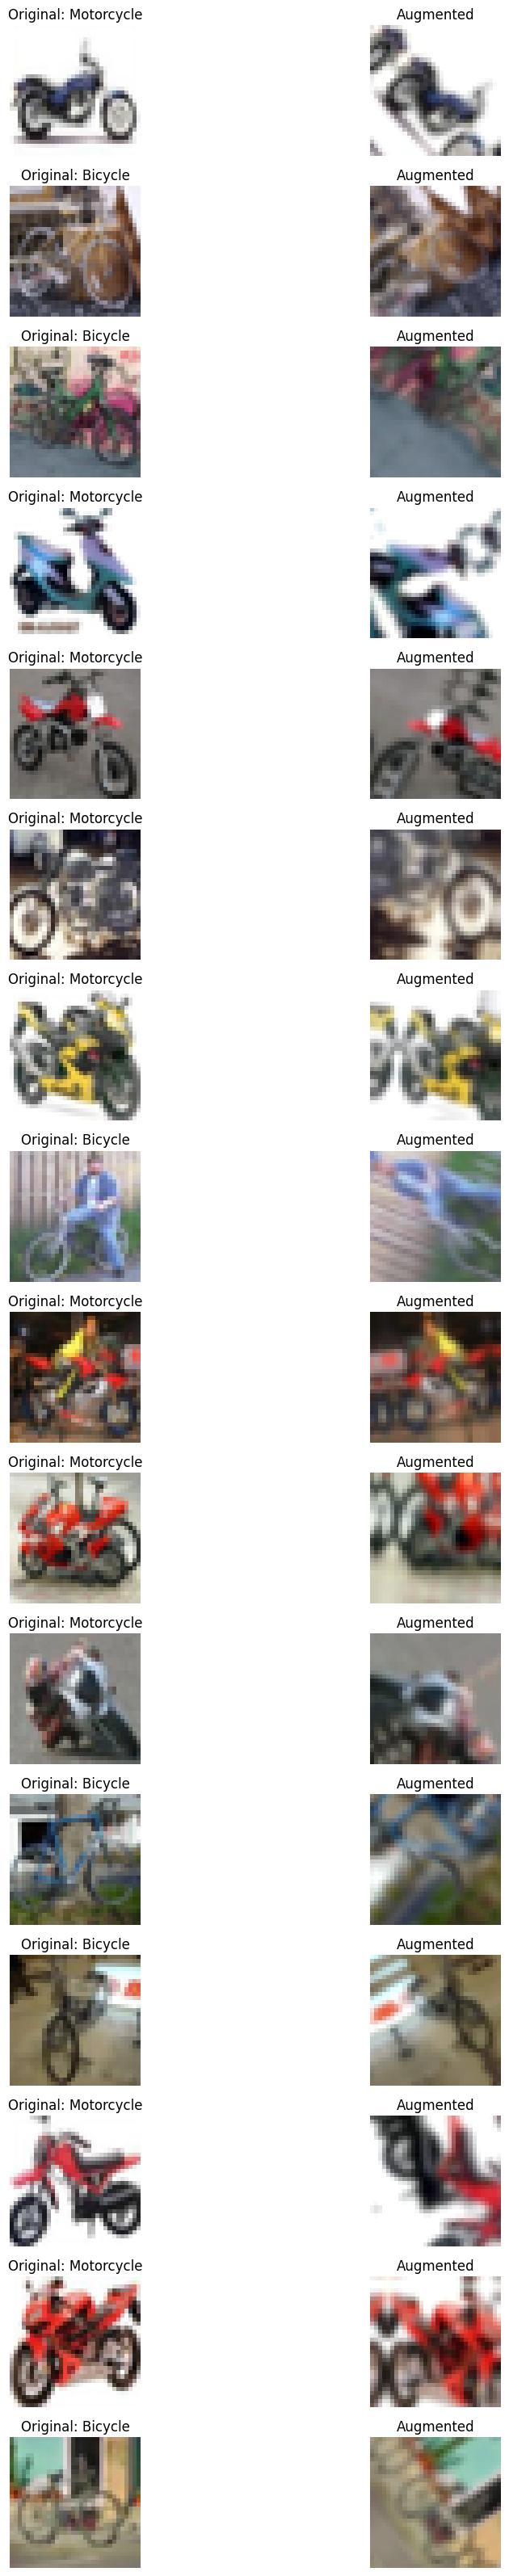

In [3]:
for batch_images, batch_labels in train_ds.take(1):
    images = batch_images[:16]
    labels = batch_labels[:16]

plt.figure(figsize=(12, 32))

for i in range(len(images)):
    image = images[i]
    x = random_translation(image)
    x = random_zoom(x)
    x = random_flip(x)
    x = random_rotation(x)
    x = random_contrast(x)

    plt.subplot(len(images), 2, 2 * i + 1)
    plt.imshow(image.numpy().astype("uint8"))
    plt.title(f"Original: {CLASS_NAMES[int(labels[i])]}")
    plt.axis("off")

    plt.subplot(len(images), 2, 2 * i + 2)
    plt.imshow(np.clip(x.numpy(), 0, 255).astype("uint8"))
    plt.title("Augmented")
    plt.axis("off")

plt.tight_layout()
plt.show()

** The additional photos created through data augmentation increase the variety of training examples by changing their position, orientation, zoom, and contrast. This helps the CNN learn important features that distinguish bicycles from motorcycles and improves its ability to classify new images.

## 3. Build the CNN

**(f)** Implement the network with the Keras Functional API. Apply augmentation, rescale RGB values to 0–1, then use two convolution-and-pooling blocks, a flattening layer, a 128-unit dense layer, and one sigmoid output. The input remains at CIFAR-100's native 32 × 32 resolution.

In [4]:
inputs = Input(shape=(32, 32, 3), name="input")

# Augmentation
x = random_translation(inputs)
x = random_zoom(x)
x = random_flip(x)
x = random_rotation(x)
x = random_contrast(x)

# Pixel scaling
x = Rescaling(1.0 / 255.0, name="rescaling")(x)

# Convolutional block 1
x = Conv2D(32, (4, 4), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)

# Convolutional block 2
x = Conv2D(32, (4, 4), activation="relu")(x)
x = MaxPooling2D((2, 2))(x)

# Classification head
x = Flatten()(x)
x = Dense(128, activation="relu")(x)
outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 32, 32, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,641 (471.25 KB)

 Trainable params: 120,641 (471.25 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Compile and train

**(g)** Compile the model with Adam, binary cross-entropy, and accuracy. Train for 10 epochs and store the training history in `history`.

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.8413 - loss: 0.3572 - val_accuracy: 0.7850 - val_loss: 0.4615
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8512 - loss: 0.3337 - val_accuracy: 0.7500 - val_loss: 0.5666
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8413 - loss: 0.3370 - val_accuracy: 0.7750 - val_loss: 0.5545
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.8475 - loss: 0.3394 - val_accuracy: 0.7950 - val_loss: 0.5146
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.8325 - loss: 0.3580 - val_accuracy: 0.8050 - val_loss: 0.4412
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8512 - loss: 0.3398 - val_accuracy: 0.8200 - val_loss: 0.4190
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8525 - loss: 0.3304 - val_accuracy: 0.7950 - val_loss: 0.4752
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8500 - loss: 0.3455 - val_accuracy: 0.

## 5. Review the training curves

**(h)** Plot training and validation loss across the completed epochs. Describe their trends and discuss any signs of overfitting.

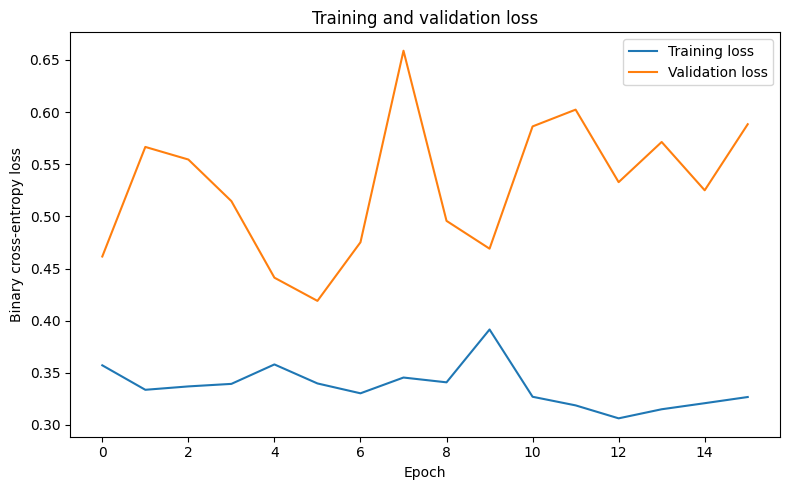

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Try predictions on individual images

**(i)** Select one motorcycle image from the held-out test set. Display the image and the model's predicted class with its confidence percentage. Here, the sigmoid output represents the predicted probability of **Motorcycle**.

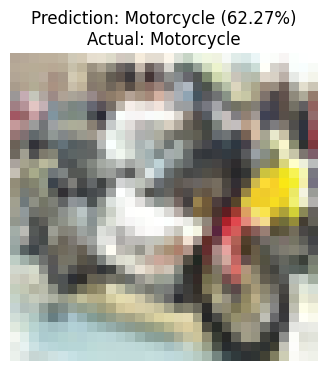

In [17]:
# Choose a known motorcycle example from the test set.
test_index = int(np.flatnonzero(y_test == 1)[0])
test_image = X_test[test_index]

proba = float(model.predict(np.expand_dims(test_image, axis=0), verbose=0)[0][0])
if proba >= 0.5:
    bicycle_or_motorcycle = "Motorcycle"
    confidence = 100 * proba
else:
    bicycle_or_motorcycle = "Bicycle"
    confidence = 100 * (1 - proba)

plt.figure(figsize=(4, 4))
plt.imshow(test_image)
plt.axis("off")
plt.title(
    f"Prediction: {bicycle_or_motorcycle} ({confidence:.2f}%)\n"
    f"Actual: {CLASS_NAMES[int(y_test[test_index])] }"
)
plt.show()

**(j)** Repeat the prediction for four more held-out images. Compare each prediction with the known label and note any mistakes.

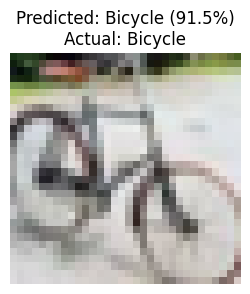

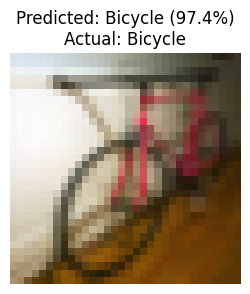

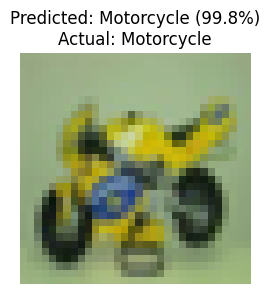

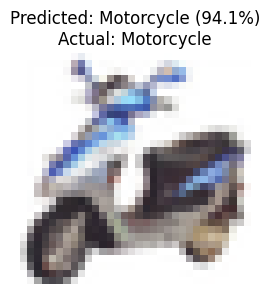

In [18]:
# Select two bicycles and two motorcycles, excluding the image shown above.
bicycle_indices = np.flatnonzero(y_test == 0)[:2]
motorcycle_indices = np.flatnonzero(y_test == 1)[1:3]
sample_indices = np.concatenate([bicycle_indices, motorcycle_indices])

for idx in sample_indices:
    test_image = X_test[idx]
    proba = float(model.predict(np.expand_dims(test_image, axis=0), verbose=0)[0][0])

    if proba >= 0.5:
        bicycle_or_motorcycle = "Motorcycle"
        confidence = 100 * proba
    else:
        bicycle_or_motorcycle = "Bicycle"
        confidence = 100 * (1 - proba)

    plt.figure(figsize=(3, 3))
    plt.imshow(test_image)
    plt.axis("off")
    plt.title(
        f"Predicted: {bicycle_or_motorcycle} ({confidence:.1f}%)\n"
        f"Actual: {CLASS_NAMES[int(y_test[idx])] }"
    )
    plt.show()

## 7. Final test-set check

Use the official test subset only after training is complete. Report accuracy and the per-class precision, recall, and F1-score, then inspect the confusion matrix. These figures should be generated by running the notebook; they are not predetermined.

Test accuracy: 0.855

              precision    recall  f1-score   support

     Bicycle      0.882     0.820     0.850       100
  Motorcycle      0.832     0.890     0.860       100

    accuracy                          0.855       200
   macro avg      0.857     0.855     0.855       200
weighted avg      0.857     0.855     0.855       200



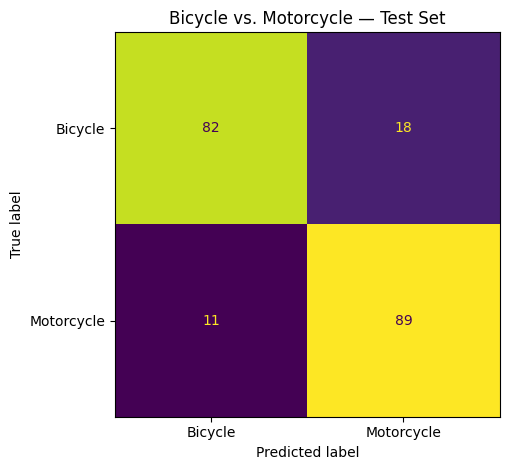

In [19]:
test_prob_motorcycle = model.predict(test_ds, verbose=0).ravel()
y_pred = (test_prob_motorcycle >= 0.5).astype("int32")

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
    digits=3,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[CLASS_NAMES[0], CLASS_NAMES[1]],
)
cm_display.plot(values_format="d", colorbar=False)
plt.title("Bicycle vs. Motorcycle — Test Set")
plt.tight_layout()
plt.show()